In [1]:
import librosa
import torch
import torchaudio
import torchaudio.functional as AF
import torchaudio.transforms as T
from IPython import display
from matplotlib import pyplot as plt
from torch import nn
from pymatreader import read_mat
import numpy as np

SEED = 42
torch.manual_seed(SEED)

In [2]:
class AudioVisualizer:
    """Draws waveform and log-mel spectrogram and plays the audio.

    MelSpectrogram transforms are cached by sample rate,
    so they are created once and reused on every call.
    """

    def __init__(
        self,
        figsize: tuple[float, float] = (20, 5),
        n_fft: int = 1024,
        win_length: int = 1024,
        hop_length: int = 256,
        n_mels: int = 80,
    ) -> None:
        self._mel_cache: dict[int, T.MelSpectrogram] = {}
        self.figsize = figsize
        self.mel_kwargs = dict(
            n_fft=n_fft, win_length=win_length, hop_length=hop_length, n_mels=n_mels
        )

    def mel(self, sr: int) -> T.MelSpectrogram:
        if sr not in self._mel_cache:
            self._mel_cache[sr] = T.MelSpectrogram(sample_rate=sr, **self.mel_kwargs)
        return self._mel_cache[sr]

    @torch.no_grad()
    def log_mel(self, wav: torch.Tensor, sr: int) -> torch.Tensor:
        # clamp: log(0) = -inf on silence
        return torch.log(self.mel(sr)(wav).clamp(min=1e-5))

    def show_spec(self, spec: torch.Tensor) -> None:
        plt.figure(figsize=self.figsize)
        plt.imshow(spec.squeeze(), origin="lower", aspect="auto")
        plt.xlabel("Frame", size=20)
        plt.ylabel("Mel bin", size=20)
        plt.show()

    def __call__(self, wav: torch.Tensor, sr: int = 22050, play: bool = True) -> None:
        wav = wav.detach().float().cpu()

        if wav.dim() == 2:
            # Any to mono audio conversion
            wav = wav.mean(dim=0)

        t = torch.arange(wav.shape[-1]) / sr
        plt.figure(figsize=self.figsize)
        plt.plot(t, wav, alpha=0.7, c="green")
        plt.grid()
        plt.xlim(0, wav.shape[-1] / sr)
        plt.xlabel("Time, s", size=20)
        plt.ylabel("Amplitude", size=20)
        plt.show()

        self.show_spec(self.log_mel(wav, sr))

        if play:
            display.display(display.Audio(wav, rate=sr, normalize=False))

In [3]:
mat_path = "./_data_for_augmentations/data_FLAIR.mat"

# Загрузка данных — возвращает словарь Python
data = read_mat(mat_path)

# Посмотреть все доступные ключи (имена переменных)
print(data.keys())

dict_keys(['__header__', '__version__', '__globals__', 'boundary_normals', 'boundary_points', 'c', 'fs', 'mic_positions', 'rirs', 'spkr_positions'])


In [4]:
rirs = torch.Tensor(data["rirs"]).mean(dim=-1).permute(1, 0)

In [5]:
data["rirs"].shape

(17873, 135, 2)

In [6]:
rirs.shape

torch.Size([135, 17873])

In [7]:
visualize_audio = AudioVisualizer()
sr_rirs = 48000

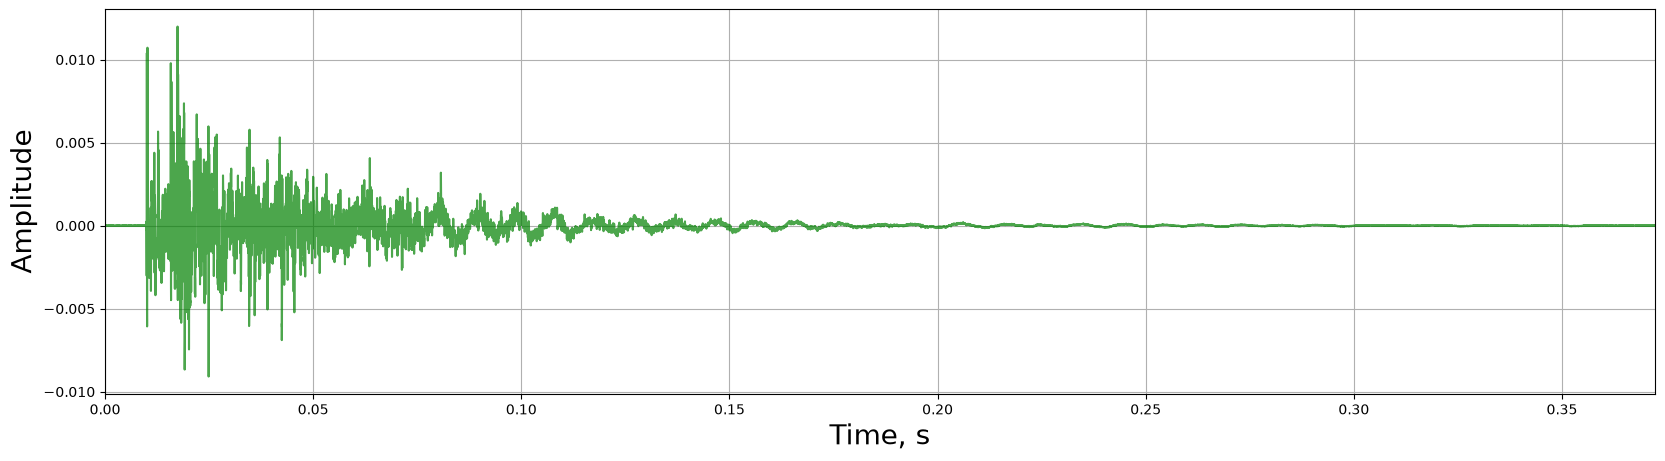

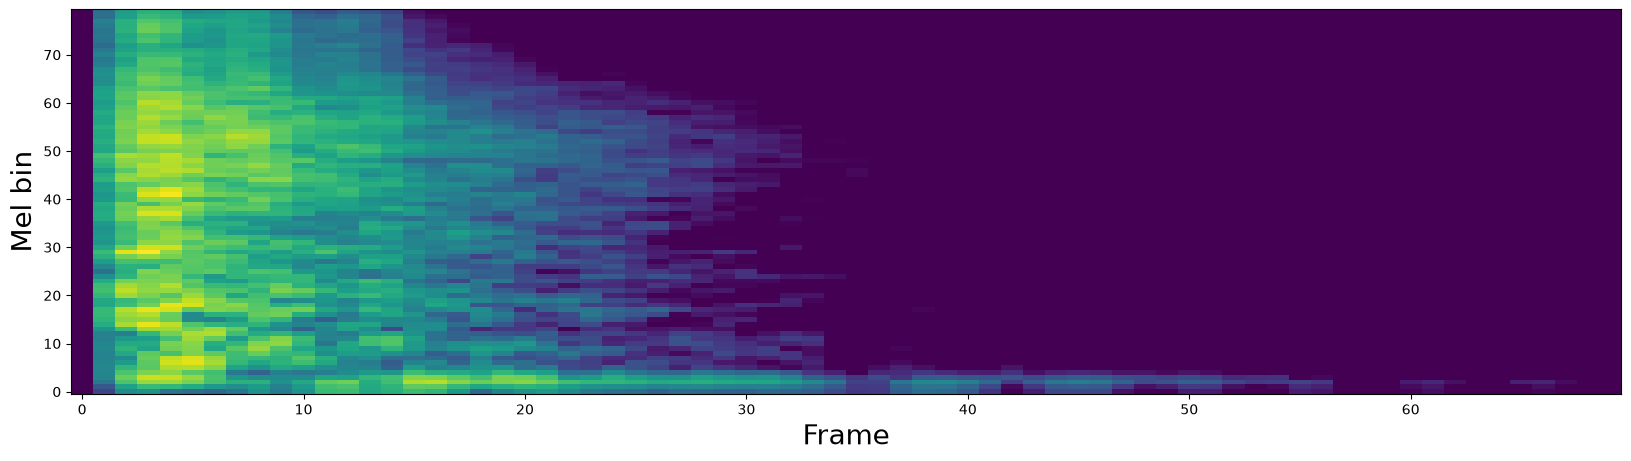

In [8]:
visualize_audio(rirs[1], sr=sr_rirs)

In [9]:
wav, sr_source = librosa.load("./_test_audio/LJ001-0001.wav")
sr_source = int(sr_source)
wav = torch.Tensor(wav).unsqueeze(0)

/home/simon/Desktop/ФКН/4 курс/DLA/dla-hw/dla-asr-1/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [10]:
wav.shape

torch.Size([1, 212893])

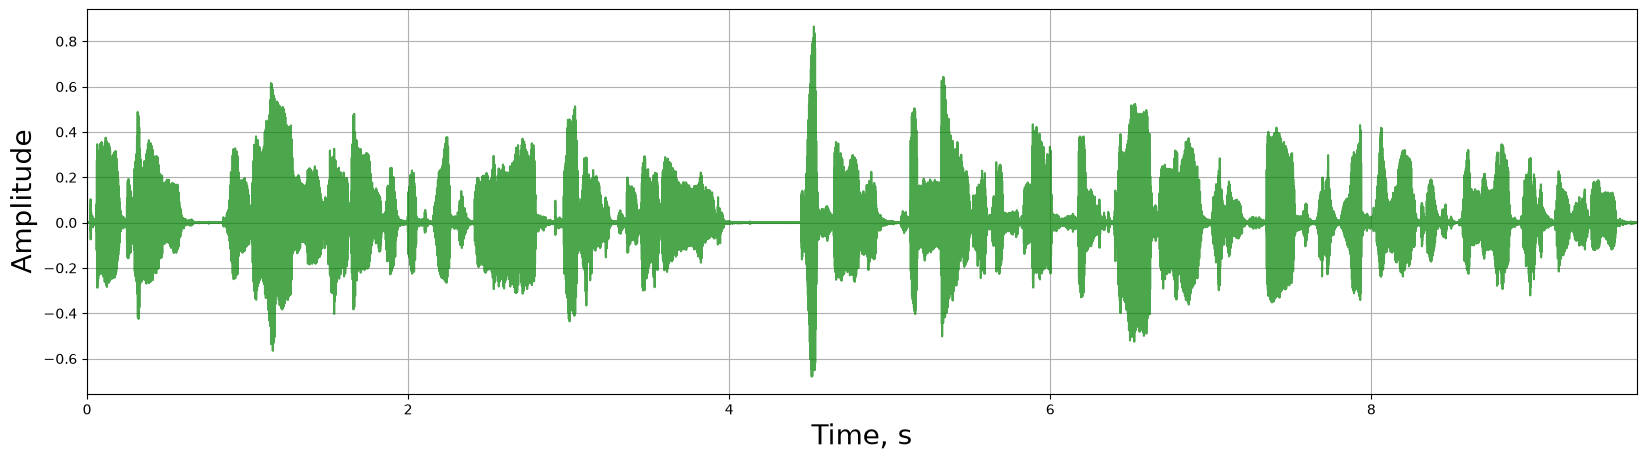

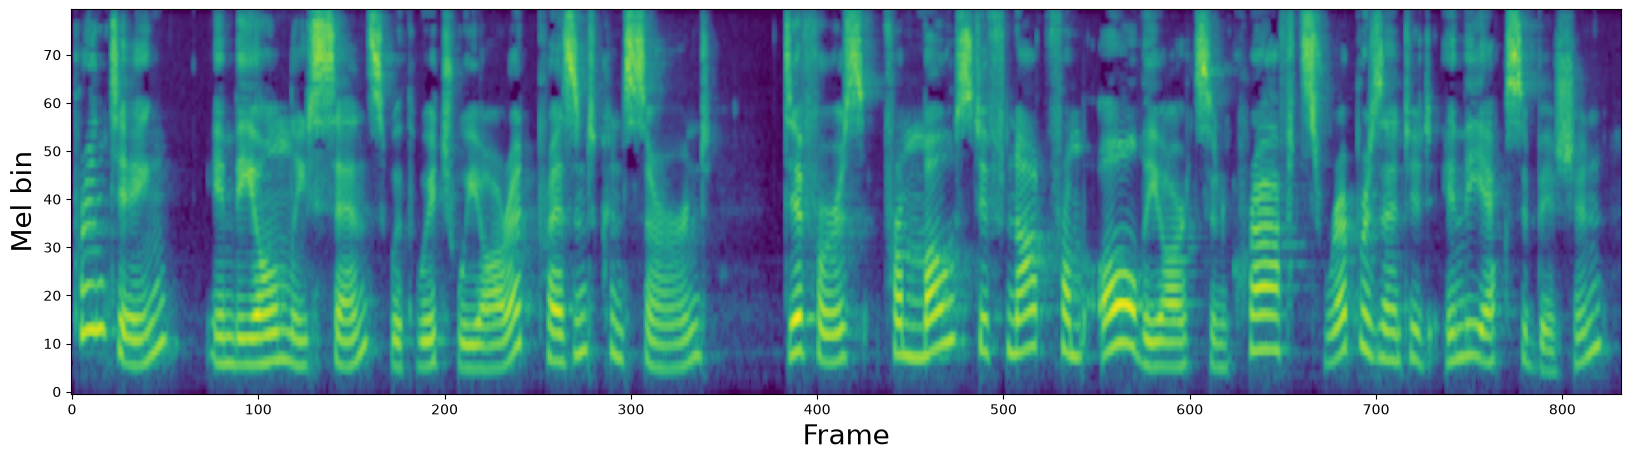

In [11]:
visualize_audio(wav, sr=sr_source)

In [23]:
from src.transforms.wav_augs import ImpulseResponseAugmentation, AddGaussNoise, RandomPitchShift, Gain

## IRA

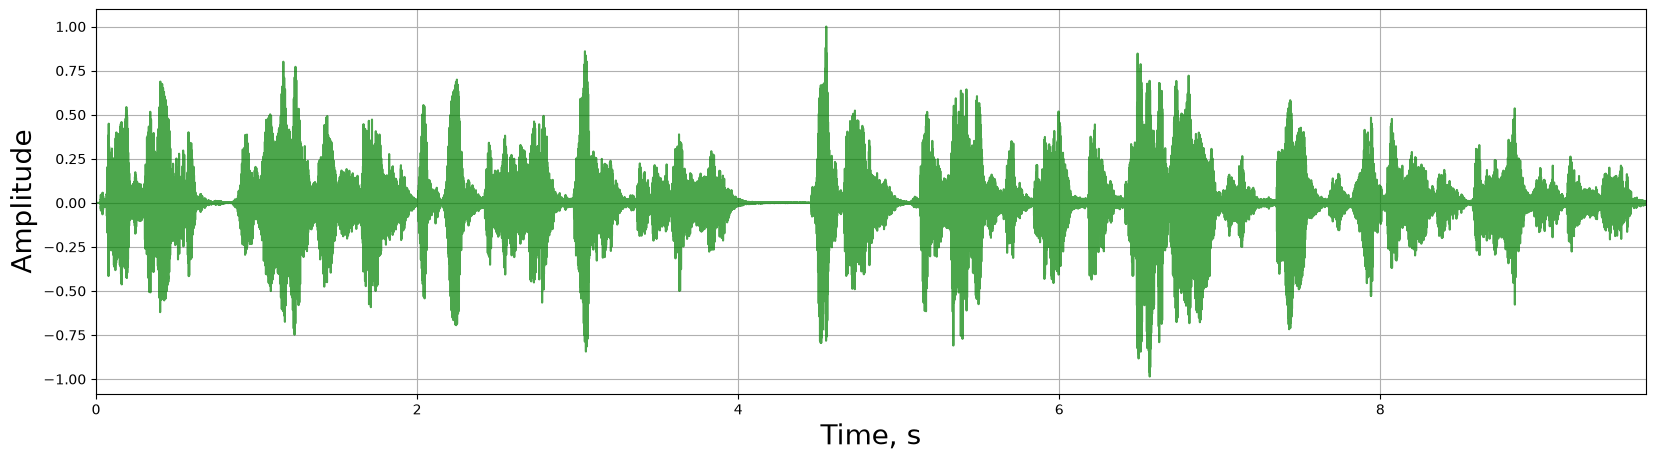

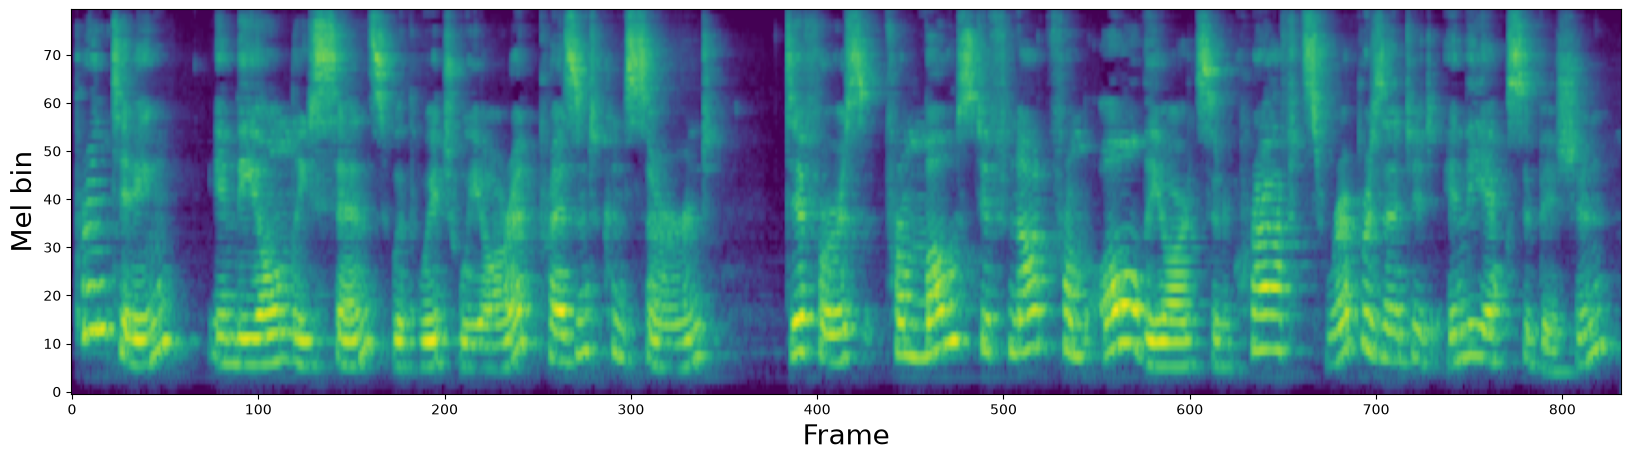

In [13]:
ira = ImpulseResponseAugmentation(sample_rate=sr_source, prob=1.0, decay_range=(0, 1), normalize_rir=False)
visualize_audio(ira(wav), sr=sr_source)

## Gain

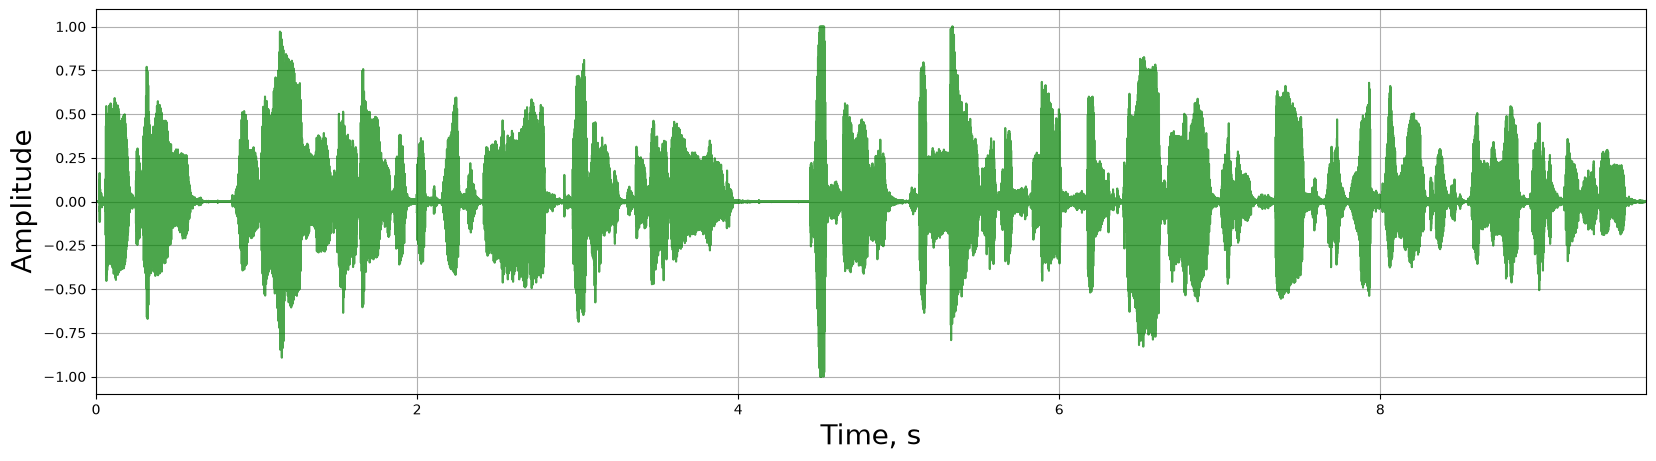

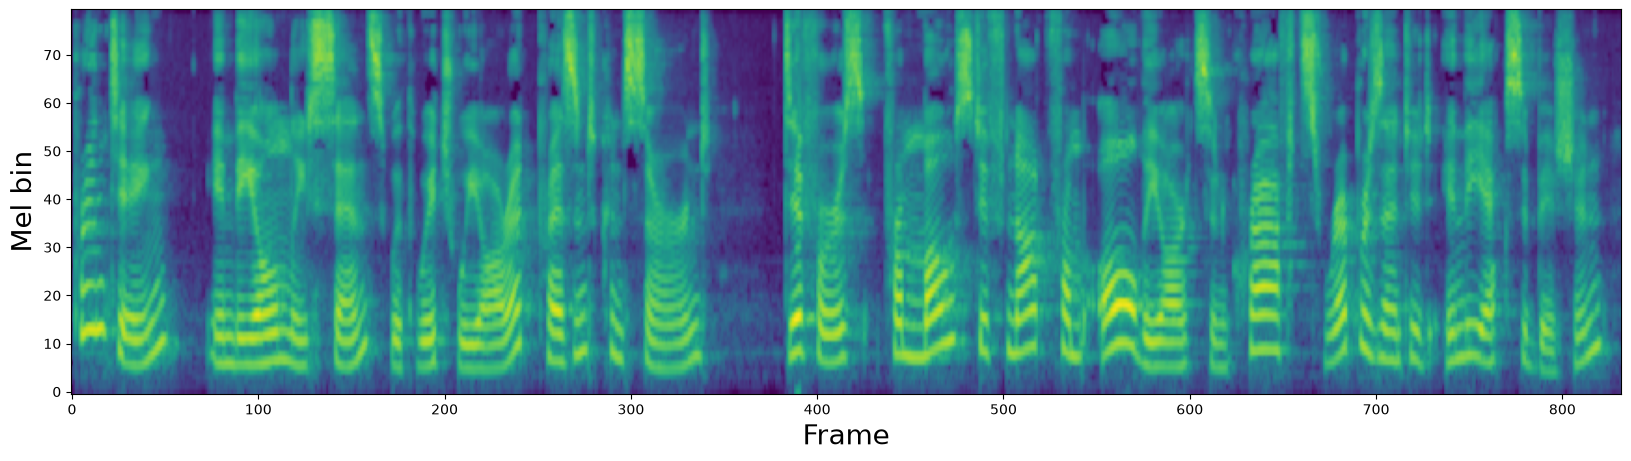

In [14]:
gain = Gain(p=1, sample_rate=sr_source)
gained = gain(wav)
visualize_audio(gained.clip(-1, 1), sr=sr_source)

## Gauss Noise

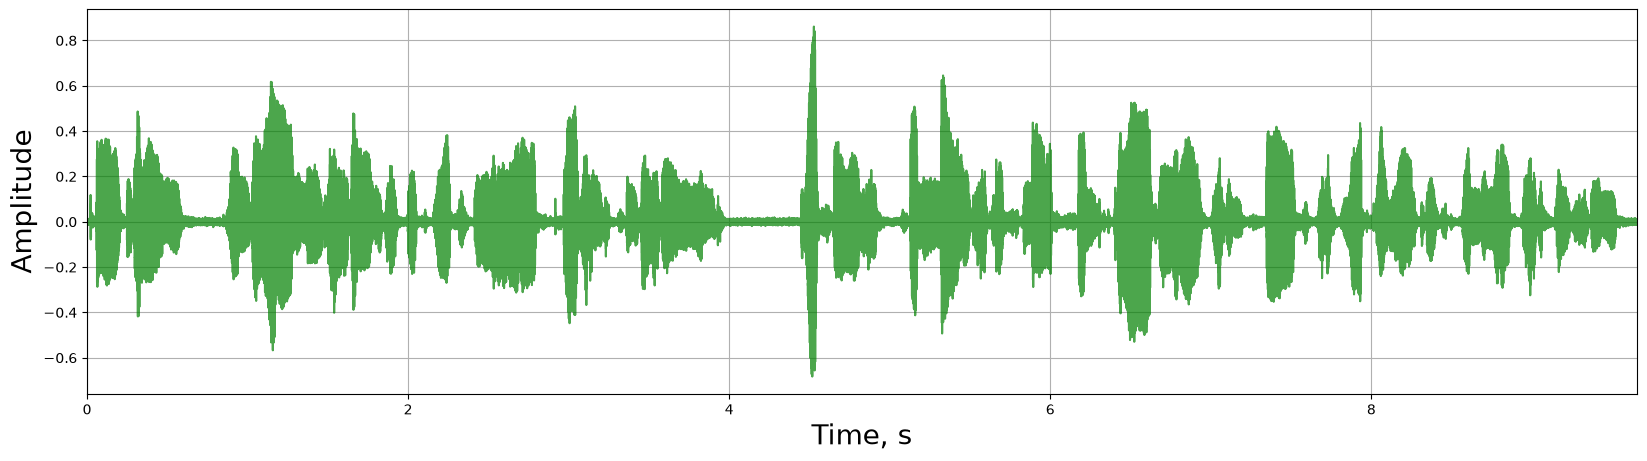

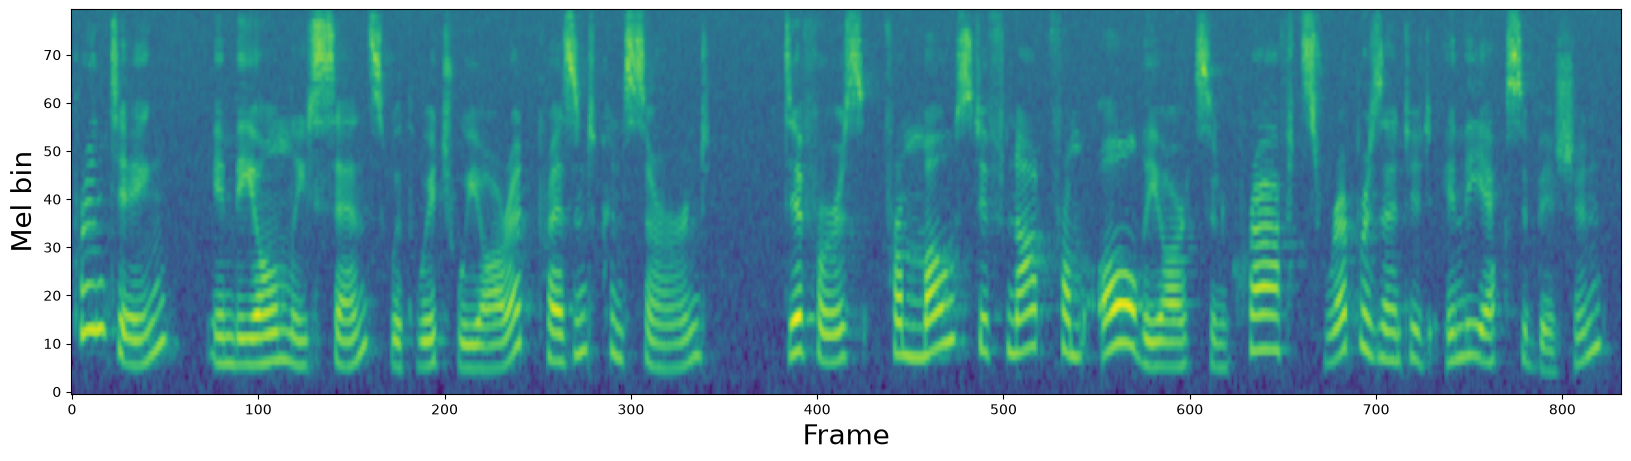

In [15]:
noiser = AddGaussNoise(prob=1, snr_db_range=torch.Tensor([25, 26]))
visualize_audio(noiser(wav).clip(-1, 1), sr=sr_source)

## Pitch Shift

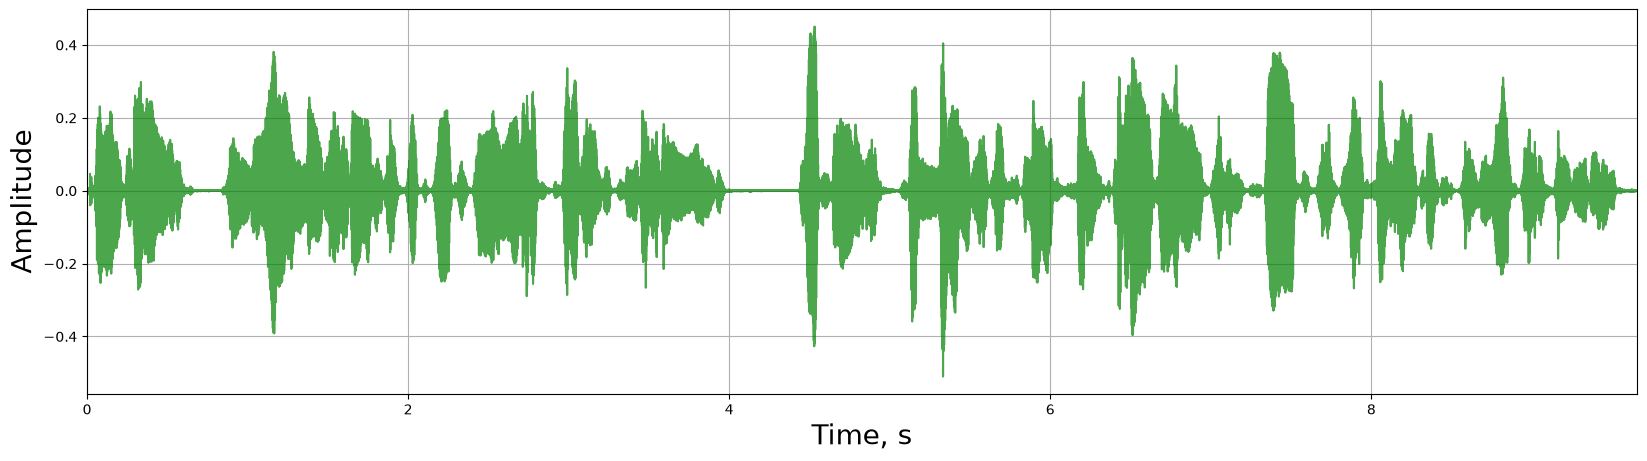

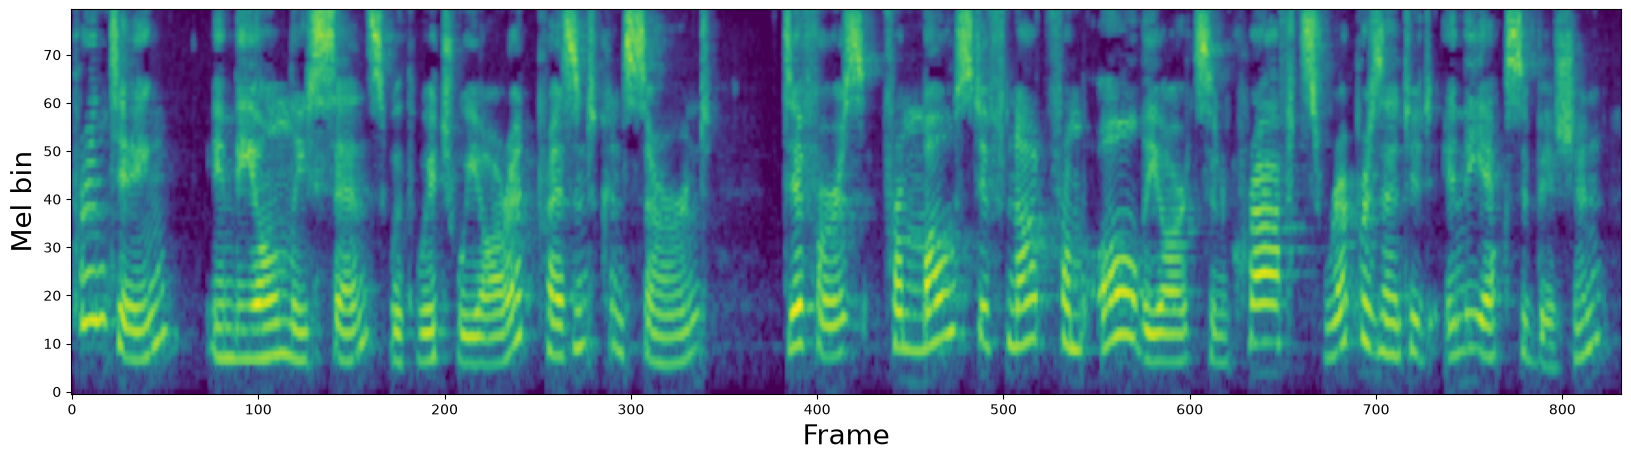

In [24]:
pitch_shifter = RandomPitchShift(prob=1.0, sample_rate=sr_source, min_steps=2, max_steps=2)
visualize_audio(pitch_shifter(wav).clip(-1, 1), sr=sr_source)